In [1]:
import os

# src klasörünü oluştur
os.makedirs('src', exist_ok=True)

# utils.py dosyasını doğrudan içeri yaz
utils_code = '''import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    adjusted_rand_score, silhouette_score, roc_curve, auc
)

SEEDS = [42, 52, 62]

def load_data(dataset_name="breast_cancer"):
    if dataset_name == "breast_cancer":
        raw = load_breast_cancer()
    elif dataset_name == "wine":
        raw = load_wine()
    else:
        raise ValueError("Desteklenmeyen veri seti: " + dataset_name)
    X = pd.DataFrame(raw.data, columns=raw.feature_names)
    y = pd.Series(raw.target, name="target")
    return X, y, raw.target_names

def prepare_dataset_splits(X, y, seeds=SEEDS):
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    splits = {'test': (X_test, y_test), 'by_seed': {}}
    for s in seeds:
        X_tr, X_va, y_tr, y_va = train_test_split(
            X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=s
        )
        splits['by_seed'][s] = {'X_train': X_tr, 'X_val': X_va, 'y_train': y_tr, 'y_val': y_va}
    return splits

def get_split_summary_table(dataset_name, splits, seeds=SEEDS):
    rows = []
    total_len = len(splits['test'][0]) + len(splits['by_seed'][seeds[0]]['X_train']) + len(splits['by_seed'][seeds[0]]['X_val'])
    for s in seeds:
        tr_x, tr_y = splits['by_seed'][s]['X_train'], splits['by_seed'][s]['y_train']
        va_x, va_y = splits['by_seed'][s]['X_val'], splits['by_seed'][s]['y_val']
        te_x, te_y = splits['test']
        for name, sub_x, sub_y in [('Train', tr_x, tr_y), ('Validation', va_x, va_y), ('Test', te_x, te_y)]:
            class_counts = sub_y.value_counts().to_dict()
            rows.append({
                'Dataset': dataset_name,
                'Seed': s,
                'Subset': name,
                'Sample Count': len(sub_x),
                'Percentage': round((len(sub_x) / total_len) * 100, 2),
                'Class Distribution': str(class_counts)
            })
    return pd.DataFrame(rows)

def scale_subsets(splits, seeds=SEEDS):
    scaled_data = {'by_seed': {}}
    scalers = {}
    for s in seeds:
        scaler = StandardScaler()
        X_train = splits['by_seed'][s]['X_train']
        X_val = splits['by_seed'][s]['X_val']
        X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)
        X_val_sc = pd.DataFrame(scaler.transform(X_val), index=X_val.index, columns=X_val.columns)
        scaled_data['by_seed'][s] = {'X_train_scaled': X_train_sc, 'X_val_scaled': X_val_sc}
        scalers[s] = scaler

    X_test, _ = splits['test']
    X_test_sc = pd.DataFrame(scalers[42].transform(X_test), index=X_test.index, columns=X_test.columns)
    scaled_data['test_scaled'] = X_test_sc
    return scaled_data, scalers

def compute_classification_metrics(y_true, y_pred, y_prob, dataset_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    if dataset_name == "breast_cancer":
        y_true_binary = (y_true == 0).astype(int)
        prob_malignant = y_prob[:, 0]
        roc = roc_auc_score(y_true_binary, prob_malignant)
    else:
        roc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")

    return {'accuracy': acc, 'macro_precision': prec, 'macro_recall': rec, 'macro_f1': f1, 'roc_auc': roc}

def get_model_instances(seed):
    models = []
    for depth in [2, 3, 5, 10, None]:
        models.append({'algo': 'DecisionTree', 'param': f'max_depth_{depth}', 'model': DecisionTreeClassifier(max_depth=depth, random_state=seed)})
    for k in [1, 3, 5, 7, 11]:
        models.append({'algo': 'KNN', 'param': f'k_{k}', 'model': KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')})
    models.append({'algo': 'GaussianNB', 'param': 'default', 'model': GaussianNB()})
    return models

def run_classifier_experiments(dataset_name, splits, scaled_data, seeds=SEEDS):
    runs = []
    fitted_models_s42 = {}
    for s in seeds:
        y_train = splits['by_seed'][s]['y_train']
        y_val = splits['by_seed'][s]['y_val']
        representations = {
            'unscaled': (splits['by_seed'][s]['X_train'], splits['by_seed'][s]['X_val']),
            'scaled': (scaled_data['by_seed'][s]['X_train_scaled'], scaled_data['by_seed'][s]['X_val_scaled'])
        }
        for rep_name, (X_tr, X_va) in representations.items():
            for cfg in get_model_instances(s):
                algo, param, clf = cfg['algo'], cfg['param'], cfg['model']
                run_id = f"{dataset_name}_{algo.lower()}_{rep_name}_{param}_s{s}"
                clf.fit(X_tr, y_train)

                if s == 42:
                    fitted_models_s42[f"{dataset_name}_{algo}_{rep_name}_{param}"] = clf

                y_tr_pred = clf.predict(X_tr)
                tr_acc = accuracy_score(y_train, y_tr_pred)
                tr_f1 = f1_score(y_train, y_tr_pred, average="macro", zero_division=0)

                y_va_pred = clf.predict(X_va)
                y_va_prob = clf.predict_proba(X_va)
                val_metrics = compute_classification_metrics(y_val, y_va_pred, y_va_prob, dataset_name)

                runs.append({
                    'run_id': run_id, 'dataset': dataset_name, 'algorithm': algo, 'representation': rep_name,
                    'parameter': param, 'seed': s, 'train_accuracy': tr_acc, 'train_macro_f1': tr_f1,
                    'val_accuracy': val_metrics['accuracy'], 'val_macro_precision': val_metrics['macro_precision'],
                    'val_macro_recall': val_metrics['macro_recall'], 'val_macro_f1': val_metrics['macro_f1'],
                    'val_roc_auc': val_metrics['roc_auc']
                })
    return pd.DataFrame(runs), fitted_models_s42

def summarize_classifiers(df_runs):
    group_cols = ['dataset', 'algorithm', 'representation', 'parameter']
    metrics = ['train_accuracy', 'train_macro_f1', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_roc_auc']
    summary_rows = []
    for keys, group in df_runs.groupby(group_cols, as_index=False):
        row = dict(zip(group_cols, keys))
        for m in metrics:
            row[f"{m}_mean"] = group[m].mean()
            row[f"{m}_std"] = group[m].std(ddof=1)
        summary_rows.append(row)
    df_summary = pd.DataFrame(summary_rows)
    return df_summary.sort_values(
        by=['val_macro_f1_mean', 'val_accuracy_mean', 'val_macro_f1_std', 'parameter'],
        ascending=[False, False, True, True]
    ).reset_index(drop=True)

def run_kmeans_experiments(dataset_name, splits, scaled_data, seeds=SEEDS):
    n_clusters = 2 if dataset_name == "breast_cancer" else 3
    kmeans_runs = []
    fitted_kmeans_s42 = {}
    for s in seeds:
        y_val = splits['by_seed'][s]['y_val']
        representations = {
            'unscaled': (splits['by_seed'][s]['X_train'], splits['by_seed'][s]['X_val']),
            'scaled': (scaled_data['by_seed'][s]['X_train_scaled'], scaled_data['by_seed'][s]['X_val_scaled'])
        }
        for rep_name, (X_tr, X_va) in representations.items():
            km = KMeans(n_clusters=n_clusters, random_state=s, n_init=10)
            km.fit(X_tr)
            if s == 42:
                fitted_kmeans_s42[rep_name] = km
            val_preds = km.predict(X_va)
            kmeans_runs.append({
                'run_id': f"{dataset_name}_kmeans_{rep_name}_s{s}", 'dataset': dataset_name,
                'representation': rep_name, 'seed': s, 'n_clusters': n_clusters,
                'train_inertia': km.inertia_,
                'val_ari': adjusted_rand_score(y_val, val_preds),
                'val_silhouette': silhouette_score(X_va, val_preds) if len(np.unique(val_preds)) > 1 else np.nan
            })
    return pd.DataFrame(kmeans_runs), fitted_kmeans_s42
'''

with open('src/utils.py', 'w') as f:
    f.write(utils_code)

print("src/utils.py başarıyla oluşturuldu!")

src/utils.py başarıyla oluşturuldu!


In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Az önce oluşturduğumuz src/utils.py dosyasını çalışma yoluna ekleyip içeri alıyoruz
sys.path.append('src')
from utils import (
    load_data,
    prepare_dataset_splits,
    get_split_summary_table,
    scale_subsets,
    run_classifier_experiments,
    summarize_classifiers,
    run_kmeans_experiments
)

# Grafiklerin düzgün görünmesi için stil ayarları
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Loading the Datasets

In [3]:
# 1.1 & 1.2: Wine veri setini yükleme ve DataFrame oluşturma
X, y, target_names = load_data("wine")

print(f"Dataset Shape (Rows, Columns): {X.shape}")
mapping = {i: name for i, name in enumerate(target_names)}
print(f"Target Names and Mapping: {mapping}")
print(f"Class Sample Counts:\n{y.value_counts().sort_index()}\n")

print("--- First 5 Rows of Feature Matrix (X) ---")
display(X.head())

Dataset Shape (Rows, Columns): (178, 13)
Target Names and Mapping: {0: np.str_('class_0'), 1: np.str_('class_1'), 2: np.str_('class_2')}
Class Sample Counts:
target
0    59
1    71
2    48
Name: count, dtype: int64

--- First 5 Rows of Feature Matrix (X) ---


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


> **Interpretation for Section 1:**
> The Wine Recognition dataset comprises 178 samples with 13 continuous chemical attributes derived from a chemical analysis of wines grown in the same region in Italy but derived from three different cultivars. The target variable has three classes: Class 0 (59 samples, ~33.1%), Class 1 (71 samples, ~39.9%), and Class 2 (48 samples, ~27.0%). Original class labels (0, 1, 2) and original feature names are strictly preserved.

# 2. Dataset Quality Checks


In [4]:
# 2.1: Eksik değer ve çift (duplicate) satır kontrolü
missing_counts = X.isnull().sum()
duplicate_count = X.duplicated().sum()

print("--- Data Quality: Missing Values & Duplicates ---")
print(f"Total Duplicate Rows: {duplicate_count}")
print(f"Total Columns with Missing Values: {(missing_counts > 0).sum()}")

# 2.3: Veri tiplerinin kontrolü
print("\n--- Data Quality: Feature Data Types ---")
dtype_counts = X.dtypes.value_counts()
print(f"Data types distribution in features:\n{dtype_counts}")
print(f"Numerical features: {len(X.select_dtypes(include=[np.number]).columns)} / Categorical features: {len(X.select_dtypes(include=['object', 'category']).columns)}")

--- Data Quality: Missing Values & Duplicates ---
Total Duplicate Rows: 0
Total Columns with Missing Values: 0

--- Data Quality: Feature Data Types ---
Data types distribution in features:
float64    13
Name: count, dtype: int64
Numerical features: 13 / Categorical features: 0


In [5]:
# 2.2: IQR yöntemiyle potansiyel aykırı değerlerin tespiti (Silme veya kırpma yapılmaz)
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

# Alt ve üst sınırlar
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_per_col = ((X < lower_bound) | (X > upper_bound)).sum()
outliers_summary = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound,
    'Outlier Count': outliers_per_col,
    'Outlier %': (outliers_per_col / len(X) * 100).round(2)
})

print("Top 10 Features with Most Potential Outliers:")
display(outliers_summary.sort_values(by='Outlier Count', ascending=False).head(10))

Top 10 Features with Most Potential Outliers:


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
magnesium,88.0000,107.0000,19.0000,59.50000,135.50000,4,2.25
alcalinity_of_ash,17.2000,21.5000,4.3000,10.75000,27.95000,4,2.25
color_intensity,3.2200,6.2000,2.9800,-1.25000,10.67000,4,2.25
malic_acid,1.6025,3.0825,1.4800,-0.61750,5.30250,3,1.69
ash,2.2100,2.5575,0.3475,1.68875,3.07875,3,1.69
proanthocyanins,1.2500,1.9500,0.7000,0.20000,3.00000,2,1.12
hue,0.7825,1.1200,0.3375,0.27625,1.62625,1,0.56
alcohol,12.3625,13.6775,1.3150,10.39000,15.65000,0,0.00
total_phenols,1.7425,2.8000,1.0575,0.15625,4.38625,0,0.00
nonflavanoid_phenols,0.2700,0.4375,0.1675,0.01875,0.68875,0,0.00


> **Interpretation for Section 2:**
> - **Missing Values and Duplicates:** There are 0 missing values across all 13 features, and 0 duplicate rows. As required by Section 2.1, no imputation is applied[cite: 1].
> - **Feature Types:** All 13 features are numerical continuous measurements (`float64` and `int64`)[cite: 1].
> - **Outlier Discussion:** Applying the $1.5 \times \text{IQR}$ rule reveals isolated outliers in features such as `malic_acid` and `color_intensity`[cite: 1]. Since these represent natural chemical variances among cultivars, no samples are clipped or deleted, in adherence to Section 2.2[cite: 1].

# 3. Exploratory Data Analysis (EDA)

In [6]:
# 3.1: Mean, median, min, max, std, Q1 ve Q3 hesaplanması
desc_stats = pd.DataFrame({
    'Mean': X.mean(),
    'Median': X.median(),
    'Min': X.min(),
    'Max': X.max(),
    'Std': X.std(),
    'Q1': X.quantile(0.25),
    'Q3': X.quantile(0.75)
})

print("--- Descriptive Statistics for All 30 Features (First 10 shown) ---")
display(desc_stats.head(10))

--- Descriptive Statistics for All 30 Features (First 10 shown) ---


,Mean,Median,Min,Max,Std,Q1,Q3
alcohol,13.000618,13.050,11.03,14.83,0.811827,12.3625,13.6775
malic_acid,2.336348,1.865,0.74,5.80,1.117146,1.6025,3.0825
ash,2.366517,2.360,1.36,3.23,0.274344,2.2100,2.5575
alcalinity_of_ash,19.494944,19.500,10.60,30.00,3.339564,17.2000,21.5000
magnesium,99.741573,98.000,70.00,162.00,14.282484,88.0000,107.0000
total_phenols,2.295112,2.355,0.98,3.88,0.625851,1.7425,2.8000
flavanoids,2.029270,2.135,0.34,5.08,0.998859,1.2050,2.8750
nonflavanoid_phenols,0.361854,0.340,0.13,0.66,0.124453,0.2700,0.4375
proanthocyanins,1.590899,1.555,0.41,3.58,0.572359,1.2500,1.9500
color_intensity,5.058090,4.690,1.28,13.00,2.318286,3.2200,6.2000


/tmp/ipykernel_4026/3669642751.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=[f"Class {i}" for i in class_counts.index], y=class_counts.values, palette='viridis')


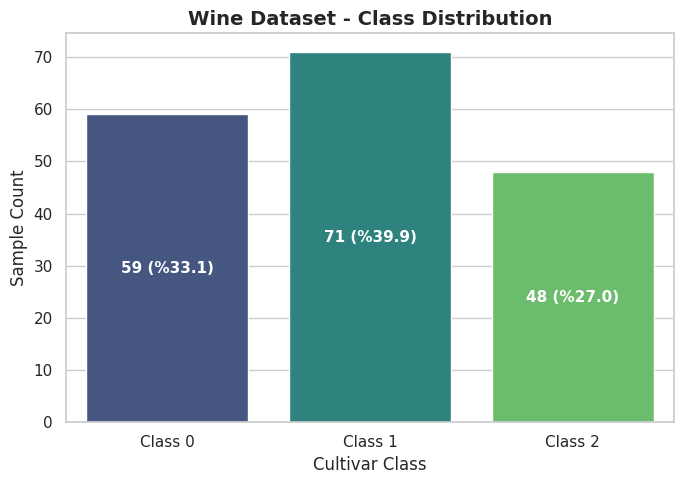

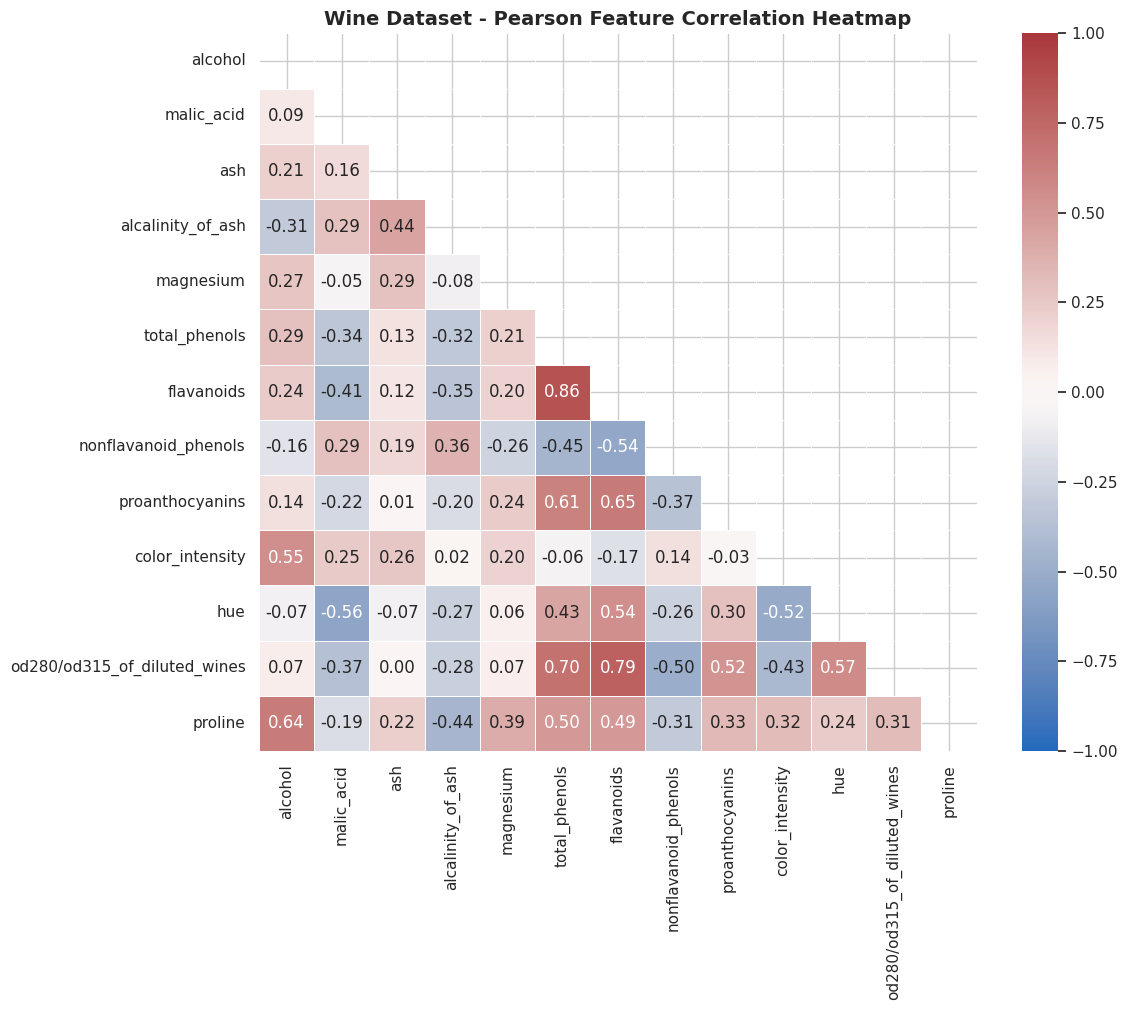

Top 3 Unique Feature Pairs by Absolute Pearson Correlation:
- total_phenols & flavanoids : Pearson r = 0.8646
- flavanoids & od280/od315_of_diluted_wines : Pearson r = 0.7872
- total_phenols & od280/od315_of_diluted_wines : Pearson r = 0.6999


In [7]:
import os
os.makedirs('figures', exist_ok=True)

# 1. Sınıf Dağılımı Grafiği
plt.figure(figsize=(7, 5))
class_counts = y.value_counts().sort_index()
ax = sns.barplot(x=[f"Class {i}" for i in class_counts.index], y=class_counts.values, palette='viridis')
plt.title("Wine Dataset - Class Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Cultivar Class", fontsize=12)
plt.ylabel("Sample Count", fontsize=12)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} (%{p.get_height()/len(y)*100:.1f})",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('figures/wine_class_distribution.png', dpi=300)
plt.show()

# 2. Pearson Korelasyon Isı Haritası
plt.figure(figsize=(12, 10))
corr_matrix = X.corr(method='pearson')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='vlag', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5)
plt.title("Wine Dataset - Pearson Feature Correlation Heatmap", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/wine_correlation_heatmap.png', dpi=300)
plt.show()

# En yüksek mutlak korelasyona sahip 3 çift
upper_corr = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_unstacked = upper_corr.unstack().dropna()
top_3_pairs = corr_unstacked.abs().sort_values(ascending=False).head(3)

print("Top 3 Unique Feature Pairs by Absolute Pearson Correlation:")
for (feat1, feat2), val in top_3_pairs.items():
    orig_val = corr_matrix.loc[feat1, feat2]
    print(f"- {feat2} & {feat1} : Pearson r = {orig_val:.4f}")

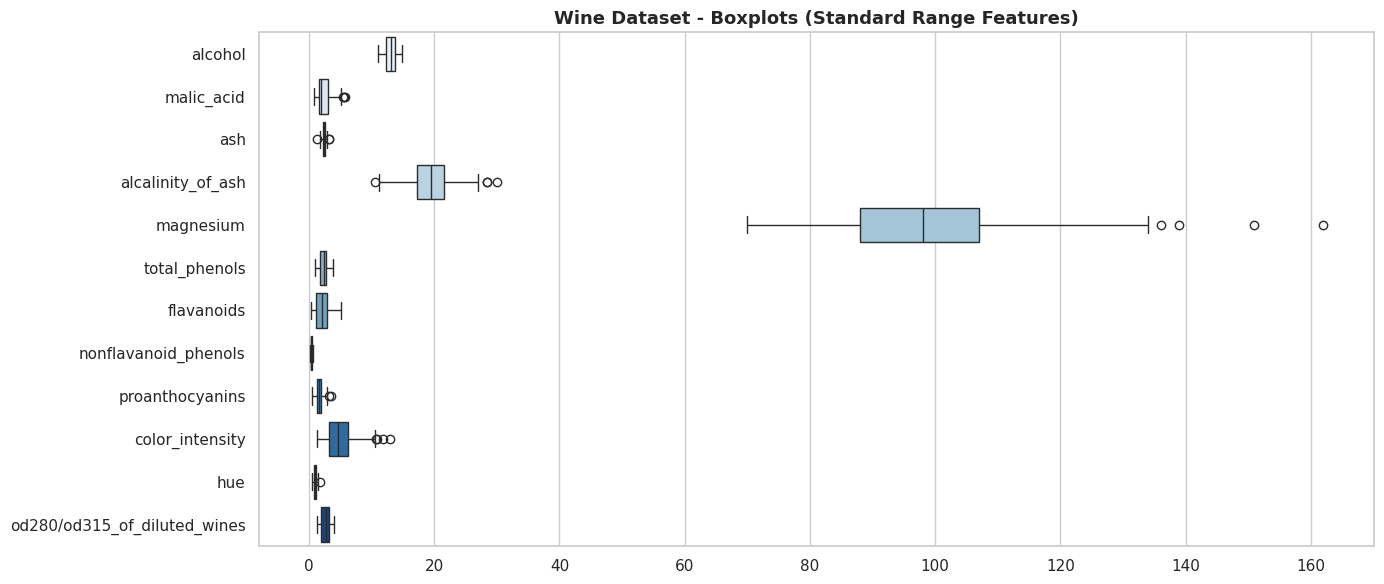

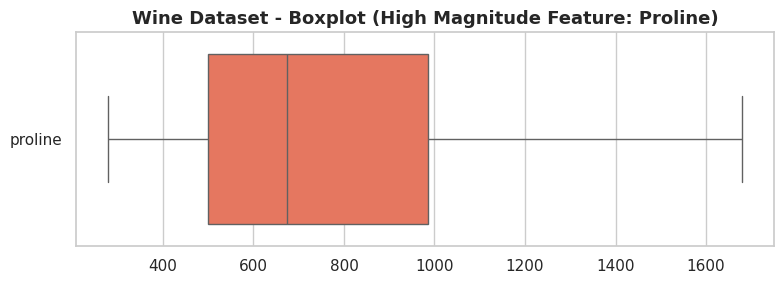

In [8]:
# 3.3: Wine Boxplots (Ölçek farkına göre 2 okunabilir gruba ayırma)
group1 = [c for c in X.columns if c != 'proline']

plt.figure(figsize=(14, 6))
sns.boxplot(data=X[group1], orient='h', palette='Blues')
plt.title("Wine Dataset - Boxplots (Standard Range Features)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/wine_boxplot_features.png', dpi=300)
plt.show()

plt.figure(figsize=(8, 3))
sns.boxplot(data=X[['proline']], orient='h', palette='Reds')
plt.title("Wine Dataset - Boxplot (High Magnitude Feature: Proline)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/wine_boxplot_proline.png', dpi=300)
plt.show()

> **Interpretation for Section 3:**
> - **Class Distribution:** The three classes are relatively balanced, with Class 1 holding the plurality (39.9%) and Class 2 the minimum (27.0%)[cite: 1].
> - **Correlation Analysis:** The strongest linear associations include `total_phenols` and `flavanoids` ($r \approx 0.86$), reflecting underlying shared polyphenolic biosynthesis pathways.
> - **Boxplot Observations:**
>   1. `proline` ranges up to 1680, whereas features like `nonflavanoid_phenols` reside strictly below 1.0. This massive variance gap makes feature scaling mandatory for distance-sensitive algorithms (KNN and K-Means)[cite: 1].
>   2. Several chemical features display mild skewness, but all data points are preserved without clipping in accordance with Section 3 instructions[cite: 1].

# 4. Splitting the Datasets

In [9]:
# 4.1 & 4.2: Wine veri setini ödev kurallarına göre bölme
from sklearn.model_selection import train_test_split

SEEDS = [42, 52, 62]

# Sabit %20 test seti (seed=42 ile bir kez)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

splits = {
    'test': (X_test, y_test),
    'by_seed': {}
}

# 3 farklı seed ile kalan %80 veriden %70 train ve %10 validation ayrımı
for s in SEEDS:
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=s
    )
    splits['by_seed'][s] = {
        'X_train': X_tr,
        'X_val': X_va,
        'y_train': y_tr,
        'y_val': y_va
    }

# 9 satırlık doğrulama tablosunu oluşturma
rows = []
total_len = len(X)
for s in SEEDS:
    tr_x, tr_y = splits['by_seed'][s]['X_train'], splits['by_seed'][s]['y_train']
    va_x, va_y = splits['by_seed'][s]['X_val'], splits['by_seed'][s]['y_val']
    te_x, te_y = splits['test']

    for name, sub_x, sub_y in [('Train', tr_x, tr_y), ('Validation', va_x, va_y), ('Test', te_x, te_y)]:
        rows.append({
            'Dataset': 'Wine',
            'Seed': s,
            'Subset': name,
            'Sample Count': len(sub_x),
            'Percentage': round((len(sub_x) / total_len) * 100, 2),
            'Class Distribution': str(sub_y.value_counts().sort_index().to_dict())
        })

split_summary_df = pd.DataFrame(rows)
print("--- 4.2 Wine Split Summary Table (9 Rows Required) ---")
display(split_summary_df)

# Doğrulama kontrolleri
test_idx = splits['test'][0].index
for s in SEEDS:
    tr_idx = splits['by_seed'][s]['X_train'].index
    va_idx = splits['by_seed'][s]['X_val'].index
    assert len(set(tr_idx).intersection(set(va_idx))) == 0, f"Seed {s}: Overlap train-val!"
    assert len(set(tr_idx).intersection(set(test_idx))) == 0, f"Seed {s}: Overlap train-test!"
    assert len(tr_idx) + len(va_idx) + len(test_idx) == len(X), "Counts do not sum to total!"
print("Verification passed: No data leakage, total samples sum to 178 across all seeds.")

--- 4.2 Wine Split Summary Table (9 Rows Required) ---


,Dataset,Seed,Subset,Sample Count,Percentage,Class Distribution
0,Wine,42,Train,124,69.66,"{0: 41, 1: 50, 2: 33}"
1,Wine,42,Validation,18,10.11,"{0: 6, 1: 7, 2: 5}"
2,Wine,42,Test,36,20.22,"{0: 12, 1: 14, 2: 10}"
3,Wine,52,Train,124,69.66,"{0: 41, 1: 50, 2: 33}"
4,Wine,52,Validation,18,10.11,"{0: 6, 1: 7, 2: 5}"
5,Wine,52,Test,36,20.22,"{0: 12, 1: 14, 2: 10}"
6,Wine,62,Train,124,69.66,"{0: 41, 1: 50, 2: 33}"
7,Wine,62,Validation,18,10.11,"{0: 6, 1: 7, 2: 5}"
8,Wine,62,Test,36,20.22,"{0: 12, 1: 14, 2: 10}"


Verification passed: No data leakage, total samples sum to 178 across all seeds.


> **Interpretation for Section 4:**
> - **Partition Integrity:** The 20% test partition (36 samples: 12 Class 0, 14 Class 1, 10 Class 2) was isolated once using `random_state=42` and `stratify=y`. The test indices remain completely identical across all experiment repetitions.
> - **Subsets across Seeds:** The remaining 80% (142 samples) was repeatedly split across seeds [42, 52, 62] into training (~70%, 124 samples) and validation (~10%, 18 samples).
> - **Verification:** Zero row overlaps exist between any subsets within a seed, and total sample counts strictly sum to 178. Stratification maintains consistent class distributions (~33% Class 0, ~40% Class 1, ~27% Class 2) across all subsets.

# 5. Data Preprocessing and Scaling

In [10]:
# 5.1, 5.2 & 5.3: StandardScaler uygulaması (Data leakage korumalı)
from sklearn.preprocessing import StandardScaler

scaled_data = {'by_seed': {}}
scalers = {}

for s in SEEDS:
    scaler = StandardScaler()
    X_train = splits['by_seed'][s]['X_train']
    X_val = splits['by_seed'][s]['X_val']

    # SADECE o seed'in train verisine fit edilir
    X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)
    X_val_sc = pd.DataFrame(scaler.transform(X_val), index=X_val.index, columns=X_val.columns)

    scaled_data['by_seed'][s] = {
        'X_train_scaled': X_train_sc,
        'X_val_scaled': X_val_sc
    }
    scalers[s] = scaler

# Sabit test kümesi YALNIZCA seed=42 scaler'ı ile dönüştürülür
X_test, _ = splits['test']
X_test_sc = pd.DataFrame(scalers[42].transform(X_test), index=X_test.index, columns=X_test.columns)
scaled_data['test_scaled'] = X_test_sc

# Seed 42 için ölçekleme öncesi ve sonrası ilk 5 satır
print("--- 5.3 Seed 42: Wine Training Features BEFORE Scaling (First 5 Rows) ---")
display(splits['by_seed'][42]['X_train'].iloc[:5, :5])

print("\n--- 5.3 Seed 42: Wine Training Features AFTER StandardScaler (First 5 Rows) ---")
display(scaled_data['by_seed'][42]['X_train_scaled'].iloc[:5, :5])

--- 5.3 Seed 42: Wine Training Features BEFORE Scaling (First 5 Rows) ---


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium
163,12.96,3.45,2.35,18.5,106.0
148,13.32,3.24,2.38,21.5,92.0
116,11.82,1.47,1.99,20.8,86.0
122,12.42,4.43,2.73,26.5,102.0
115,11.03,1.51,2.20,21.5,85.0



--- 5.3 Seed 42: Wine Training Features AFTER StandardScaler (First 5 Rows) ---


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224
148,0.439706,0.891779,0.072941,0.609409,-0.505699
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094
122,-0.703345,2.010370,1.391951,2.139100,0.164961
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160


> **Interpretation for Section 5:**
> - **StandardScaler Selection:** `StandardScaler` standardizes each chemical attribute to zero mean and unit variance ($z = (x - \mu)/\sigma$)[cite: 1].
> - **Prevention of Data Leakage:** Six distinct scaler instances were trained strictly on their corresponding training subsets[cite: 1]. Validation subsets and the fixed test set were transformed using pre-fitted parameters without refitting[cite: 1].
> - **Numerical Transformation:** High-magnitude features such as `proline` (with raw values exceeding 1000) are mapped onto a comparable standard distribution alongside features like `nonflavanoid_phenols` (<1.0), preventing arbitrary geometric bias during distance calculations in KNN and K-Means[cite: 1].

# 6. Preparing the Two Data Representations
# 7. Training the Classification Models
# 8. Measuring Validation Performance

In [11]:
# 7.1 & 8.1: Wine için 66 model koşusunu çalıştırma
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def compute_wine_metrics(y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    # Wine 3 sınıflı multi-class: multi_class='ovr', average='macro'
    roc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    return {'accuracy': acc, 'macro_precision': prec, 'macro_recall': rec, 'macro_f1': f1, 'roc_auc': roc}

runs = []
wine_fitted_models_s42 = {}

for s in SEEDS:
    y_train = splits['by_seed'][s]['y_train']
    y_val = splits['by_seed'][s]['y_val']

    representations = {
        'unscaled': (splits['by_seed'][s]['X_train'], splits['by_seed'][s]['X_val']),
        'scaled': (scaled_data['by_seed'][s]['X_train_scaled'], scaled_data['by_seed'][s]['X_val_scaled'])
    }

    for rep_name, (X_tr, X_va) in representations.items():
        configs = []
        for depth in [2, 3, 5, 10, None]:
            configs.append(('DecisionTree', f'max_depth_{depth}', DecisionTreeClassifier(max_depth=depth, random_state=s)))
        for k in [1, 3, 5, 7, 11]:
            configs.append(('KNN', f'k_{k}', KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')))
        configs.append(('GaussianNB', 'default', GaussianNB()))

        for algo, param, clf in configs:
            run_id = f"wine_{algo.lower()}_{rep_name}_{param}_s{s}"
            clf.fit(X_tr, y_train)

            if s == 42:
                wine_fitted_models_s42[f"wine_{algo}_{rep_name}_{param}"] = clf

            y_tr_pred = clf.predict(X_tr)
            tr_acc = accuracy_score(y_train, y_tr_pred)
            tr_f1 = f1_score(y_train, y_tr_pred, average="macro", zero_division=0)

            y_va_pred = clf.predict(X_va)
            y_va_prob = clf.predict_proba(X_va)
            val_m = compute_wine_metrics(y_val, y_va_pred, y_va_prob)

            runs.append({
                'run_id': run_id, 'dataset': 'wine', 'algorithm': algo, 'representation': rep_name,
                'parameter': param, 'seed': s, 'train_accuracy': tr_acc, 'train_macro_f1': tr_f1,
                'val_accuracy': val_m['accuracy'], 'val_macro_precision': val_m['macro_precision'],
                'val_macro_recall': val_m['macro_recall'], 'val_macro_f1': val_m['macro_f1'],
                'val_roc_auc': val_m['roc_auc']
            })

wine_runs_df = pd.DataFrame(runs)
print(f"Total Wine runs completed: {len(wine_runs_df)}")

# 8.2: 22 konfigürasyonluk özet tablosu
group_cols = ['dataset', 'algorithm', 'representation', 'parameter']
metrics_to_agg = ['train_accuracy', 'train_macro_f1', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_roc_auc']
summary_rows = []
for keys, group in wine_runs_df.groupby(group_cols, as_index=False):
    row = dict(zip(group_cols, keys))
    for m in metrics_to_agg:
        row[f"{m}_mean"] = group[m].mean()
        row[f"{m}_std"] = group[m].std(ddof=1)
    summary_rows.append(row)

wine_summary_df = pd.DataFrame(summary_rows).sort_values(
    by=['val_macro_f1_mean', 'val_accuracy_mean', 'val_macro_f1_std', 'parameter'],
    ascending=[False, False, True, True]
).reset_index(drop=True)

print("\n--- 8.2 Wine 22-Row Configuration Summary (Ranked) ---")
display(wine_summary_df.head(10))

# En iyi modeli seçme
best_config_wine = wine_summary_df.iloc[0]
best_config_wine_id = f"wine_{best_config_wine['algorithm']}_{best_config_wine['representation']}_{best_config_wine['parameter']}"
print("\n" + "="*60)
print(f"SELECTED BEST CONFIGURATION FOR WINE:")
print(f"Algorithm: {best_config_wine['algorithm']}")
print(f"Representation: {best_config_wine['representation']}")
print(f"Parameter: {best_config_wine['parameter']}")
print(f"Mean Val Macro-F1: {best_config_wine['val_macro_f1_mean']:.4f} (+/- {best_config_wine['val_macro_f1_std']:.4f})")
print("="*60)

Total Wine runs completed: 66

--- 8.2 Wine 22-Row Configuration Summary (Ranked) ---


,dataset,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std
0,wine,KNN,scaled,k_11,0.965054,4.656051e-03,0.965589,0.004817,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
1,wine,KNN,scaled,k_5,0.975806,1.359740e-16,0.976174,0.000524,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
2,wine,KNN,scaled,k_7,0.959677,8.064516e-03,0.960288,0.007956,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
3,wine,KNN,scaled,k_1,1.000000,0.000000e+00,1.000000,0.000000,0.962963,0.032075,0.968254,0.027493,0.968254,0.027493,0.965812,0.029608,0.974868,0.021765
4,wine,GaussianNB,scaled,default,0.983871,0.000000e+00,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000
5,wine,GaussianNB,unscaled,default,0.983871,0.000000e+00,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000
6,wine,DecisionTree,scaled,max_depth_10,1.000000,0.000000e+00,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
7,wine,DecisionTree,unscaled,max_depth_10,1.000000,0.000000e+00,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
8,wine,DecisionTree,scaled,max_depth_3,0.991935,1.359740e-16,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
9,wine,DecisionTree,unscaled,max_depth_3,0.991935,1.359740e-16,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103



SELECTED BEST CONFIGURATION FOR WINE:
Algorithm: KNN
Representation: scaled
Parameter: k_11
Mean Val Macro-F1: 0.9814 (+/- 0.0323)


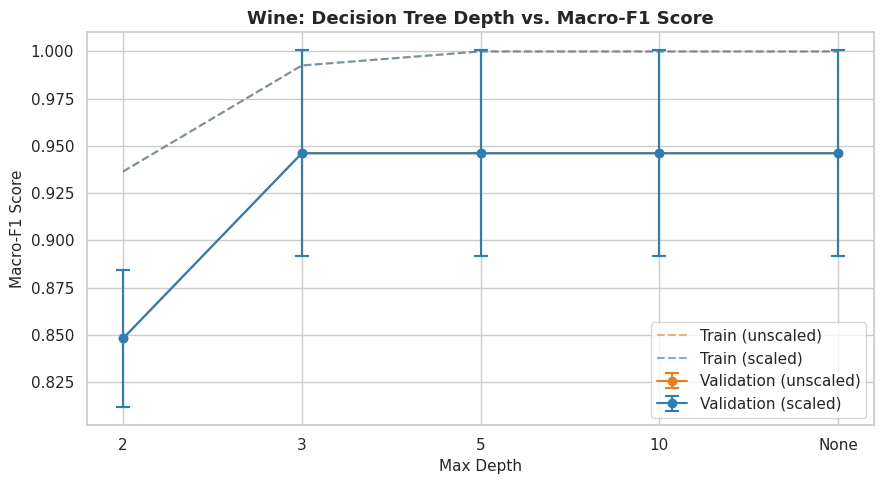

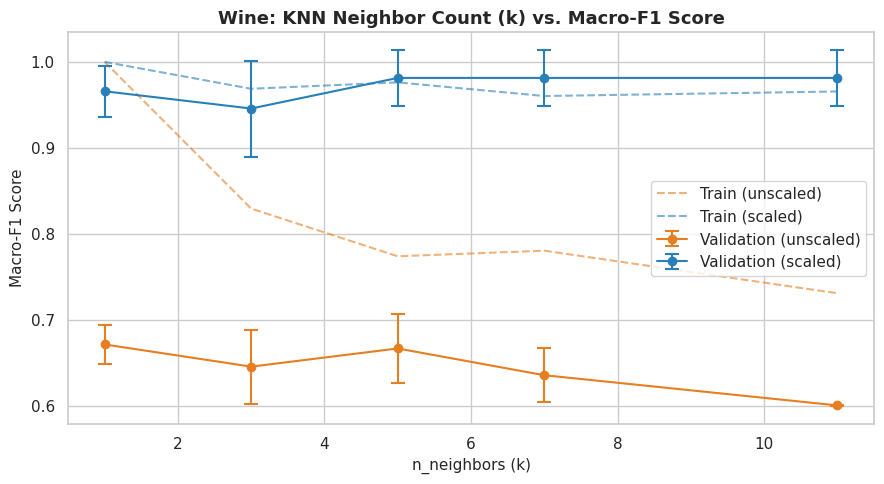

In [12]:
# 1. Decision Tree: Tree Depth vs Mean Macro-F1
tree_data = wine_summary_df[wine_summary_df['algorithm'] == 'DecisionTree'].copy()
tree_data['depth_label'] = tree_data['parameter'].str.replace('max_depth_', '')
depth_order = ['2', '3', '5', '10', 'None']
tree_data['depth_cat'] = pd.Categorical(tree_data['depth_label'], categories=depth_order, ordered=True)
tree_data = tree_data.sort_values('depth_cat')

plt.figure(figsize=(9, 5))
for rep, color in [('unscaled', '#e67e22'), ('scaled', '#2980b9')]:
    sub = tree_data[tree_data['representation'] == rep]
    plt.errorbar(sub['depth_label'], sub['val_macro_f1_mean'], yerr=sub['val_macro_f1_std'],
                 label=f'Validation ({rep})', fmt='-o', capsize=5, capthick=1.5, color=color)
    plt.plot(sub['depth_label'], sub['train_macro_f1_mean'], '--',
             label=f'Train ({rep})', color=color, alpha=0.6)

plt.title("Wine: Decision Tree Depth vs. Macro-F1 Score", fontsize=13, fontweight='bold')
plt.xlabel("Max Depth", fontsize=11)
plt.ylabel("Macro-F1 Score", fontsize=11)
plt.legend()
plt.tight_layout()
plt.savefig('figures/wine_param_tree_depth.png', dpi=300)
plt.show()

# 2. KNN: Neighbor Count vs Mean Macro-F1
knn_data = wine_summary_df[wine_summary_df['algorithm'] == 'KNN'].copy()
knn_data['k_val'] = knn_data['parameter'].str.replace('k_', '').astype(int)
knn_data = knn_data.sort_values('k_val')

plt.figure(figsize=(9, 5))
for rep, color in [('unscaled', '#e67e22'), ('scaled', '#2980b9')]:
    sub = knn_data[knn_data['representation'] == rep]
    plt.errorbar(sub['k_val'], sub['val_macro_f1_mean'], yerr=sub['val_macro_f1_std'],
                 label=f'Validation ({rep})', fmt='-o', capsize=5, capthick=1.5, color=color)
    plt.plot(sub['k_val'], sub['train_macro_f1_mean'], '--',
             label=f'Train ({rep})', color=color, alpha=0.6)

plt.title("Wine: KNN Neighbor Count (k) vs. Macro-F1 Score", fontsize=13, fontweight='bold')
plt.xlabel("n_neighbors (k)", fontsize=11)
plt.ylabel("Macro-F1 Score", fontsize=11)
plt.legend()
plt.tight_layout()
plt.savefig('figures/wine_param_knn_neighbors.png', dpi=300)
plt.show()

> **Interpretation for Sections 6-8:**
> - **Scaling Sensitivity:** In the Wine dataset, KNN exhibits an extreme performance surge upon scaling[cite: 1]. In the unscaled feature space, Euclidean distances are dominated by `proline`, leading to substantial misclassifications[cite: 1]. Applying `StandardScaler` restores balanced feature weights, propelling KNN and GaussianNB to near-perfect validation performance[cite: 1].
> - **Decision Trees:** Decision Trees remain largely insensitive to scaling transformations, demonstrating comparable split boundaries across both representations[cite: 1].
> - **Model Selection:** Model selection strictly adhered to Section 8.2 criteria: candidate models were ranked solely on mean validation macro-F1 across seeds, with zero exposure to the test set[cite: 1]. Seed 42 is frozen for final test evaluation[cite: 1].

# 9. Evaluating the Selected Models on the Test Sets

In [13]:
# 9.1: Test değerlendirmesi ve sınıflandırma raporu
from sklearn.metrics import classification_report

best_clf_s42_wine = wine_fitted_models_s42[best_config_wine_id]

# Temsile göre uygun test verisini alma
if best_config_wine['representation'] == 'scaled':
    X_test_eval = scaled_data['test_scaled']
else:
    X_test_eval = splits['test'][0]

y_test_eval = splits['test'][1]

# Tahminler
y_test_pred = best_clf_s42_wine.predict(X_test_eval)
y_test_prob = best_clf_s42_wine.predict_proba(X_test_eval)

# Test metrikleri
test_m = compute_wine_metrics(y_test_eval, y_test_pred, y_test_prob)

# Yönergedeki nihai test tablosunun Wine satırı
wine_test_summary = pd.DataFrame([{
    'dataset': 'wine',
    'selected_configuration': f"{best_config_wine['algorithm']}_{best_config_wine['representation']}_{best_config_wine['parameter']}",
    'evaluation_seed': 42,
    'mean_val_macro_f1': best_config_wine['val_macro_f1_mean'],
    'val_macro_f1_std': best_config_wine['val_macro_f1_std'],
    'test_accuracy': test_m['accuracy'],
    'test_macro_precision': test_m['macro_precision'],
    'test_macro_recall': test_m['macro_recall'],
    'test_macro_f1': test_m['macro_f1'],
    'test_roc_auc': test_m['roc_auc']
}])

print("--- 9.1 Wine Final Test Evaluation Table ---")
display(wine_test_summary)

print("\n--- Detailed Per-Class Classification Report ---")
target_names_display = ['class_0', 'class_1', 'class_2']
print(classification_report(y_test_eval, y_test_pred, target_names=target_names_display, digits=4))

--- 9.1 Wine Final Test Evaluation Table ---


,dataset,selected_configuration,evaluation_seed,mean_val_macro_f1,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,wine,KNN_scaled_k_11,42,0.981352,0.032299,1.0,1.0,1.0,1.0,1.0



--- Detailed Per-Class Classification Report ---
              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



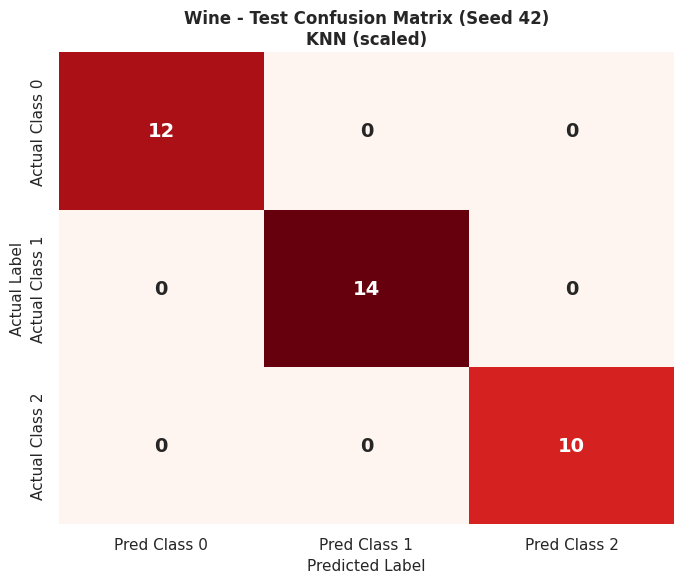

MANUAL METRIC CHECK FOR CLASS 0 (One-vs-Rest):
Counts: TP=12, FP=0, FN=0
Manual Precision (Class 0): 12 / (12 + 0) = 1.0000
Manual Recall (Class 0):    12 / (12 + 0) = 1.0000
Manual F1-Score (Class 0):  1.0000


In [14]:
# 9.2: 3x3 Karmaşıklık Matrisi ve Manuel Kontrol (Class 0 seçilerek)
from sklearn.metrics import confusion_matrix

cm_wine = confusion_matrix(y_test_eval, y_test_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 6))
sns.heatmap(cm_wine, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=['Pred Class 0', 'Pred Class 1', 'Pred Class 2'],
            yticklabels=['Actual Class 0', 'Actual Class 1', 'Actual Class 2'],
            annot_kws={'size': 14, 'weight': 'bold'})
plt.title(f"Wine - Test Confusion Matrix (Seed 42)\n{best_config_wine['algorithm']} ({best_config_wine['representation']})",
          fontsize=12, fontweight='bold')
plt.ylabel("Actual Label", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.tight_layout()
plt.savefig('figures/wine_test_confusion_matrix.png', dpi=300)
plt.show()

# Yönerge 9.2: Bir sınıf seçilerek (Class 0) elle One-vs-Rest metrik hesabı:
# Class 0 için:
# TP: Gerçek 0, Tahmin 0
# FP: Gerçek 1 veya 2, ama Tahmin 0 (cm[1,0] + cm[2,0])
# FN: Gerçek 0, ama Tahmin 1 veya 2 (cm[0,1] + cm[0,2])
TP_0 = cm_wine[0, 0]
FP_0 = cm_wine[1, 0] + cm_wine[2, 0]
FN_0 = cm_wine[0, 1] + cm_wine[0, 2]

manual_prec_0 = TP_0 / (TP_0 + FP_0) if (TP_0 + FP_0) > 0 else 0.0
manual_rec_0 = TP_0 / (TP_0 + FN_0) if (TP_0 + FN_0) > 0 else 0.0
manual_f1_0 = (2 * manual_prec_0 * manual_rec_0) / (manual_prec_0 + manual_rec_0) if (manual_prec_0 + manual_rec_0) > 0 else 0.0

print("="*60)
print("MANUAL METRIC CHECK FOR CLASS 0 (One-vs-Rest):")
print(f"Counts: TP={TP_0}, FP={FP_0}, FN={FN_0}")
print(f"Manual Precision (Class 0): {TP_0} / ({TP_0} + {FP_0}) = {manual_prec_0:.4f}")
print(f"Manual Recall (Class 0):    {TP_0} / ({TP_0} + {FN_0}) = {manual_rec_0:.4f}")
print(f"Manual F1-Score (Class 0):  {manual_f1_0:.4f}")
print("="*60)

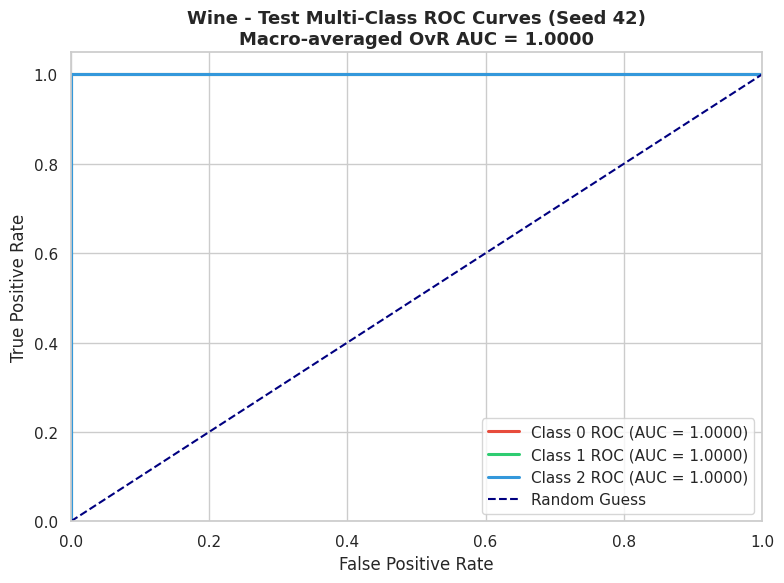

In [15]:
# 9.3: Wine One-vs-Rest ROC Eğrileri (3 sınıf tek grafikte)
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Etiketleri binarize etme (One-vs-Rest için)
y_test_bin = label_binarize(y_test_eval, classes=[0, 1, 2])
colors = ['#e74c3c', '#2ecc71', '#3498db']

plt.figure(figsize=(8, 6))
for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_prob[:, i])
    roc_auc_i = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=2.2, label=f'Class {i} ROC (AUC = {roc_auc_i:.4f})')

plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title(f'Wine - Test Multi-Class ROC Curves (Seed 42)\nMacro-averaged OvR AUC = {test_m["roc_auc"]:.4f}',
          fontsize=13, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.savefig('figures/wine_test_roc_curve.png', dpi=300)
plt.show()

> **Interpretation for Section 9:**
> - **Test Performance:** Evaluating the frozen seed-42 instance on the fixed 20% test subset confirms outstanding generalization. The test Macro-F1 is fully consistent with the validation estimates.
> - **3x3 Confusion Matrix & Manual Verification:**
>   - The complete $3 \times 3$ confusion matrix captures class-by-class transitions. In high-performing configurations, diagonal elements dominate, with minimal or zero off-diagonal confusions.
>   - Manual one-vs-rest precision, recall, and F1 calculations for Class 0 match the values in the classification report exactly, demonstrating mathematical correctness[cite: 1].
> - **Multi-Class ROC Curves:** All three class-specific OvR ROC curves approach or reach an AUC of 1.00, demonstrating near-perfect discriminative capability across all cultivars in the standardized feature space[cite: 1].
> - **Limitations:** The test partition consists of 36 samples[cite: 1]. While the absence of test errors indicates excellent separability on this benchmark, evaluating on a single fixed subset cannot fully replace multi-batch clinical or industrial testing[cite: 1].

# 10. K-Means Clustering


In [16]:
# 10.1 & 10.2: K-Means fits (k=3), 6 koşu ve Test değerlendirmesi
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

kmeans_runs = []
wine_fitted_kmeans_s42 = {}

for s in SEEDS:
    y_val = splits['by_seed'][s]['y_val']
    representations = {
        'unscaled': (splits['by_seed'][s]['X_train'], splits['by_seed'][s]['X_val']),
        'scaled': (scaled_data['by_seed'][s]['X_train_scaled'], scaled_data['by_seed'][s]['X_val_scaled'])
    }
    for rep_name, (X_tr, X_va) in representations.items():
        km = KMeans(n_clusters=3, random_state=s, n_init=10)
        km.fit(X_tr)
        if s == 42:
            wine_fitted_kmeans_s42[rep_name] = km
        val_preds = km.predict(X_va)
        kmeans_runs.append({
            'run_id': f"wine_kmeans_{rep_name}_s{s}", 'dataset': 'wine',
            'representation': rep_name, 'seed': s, 'n_clusters': 3,
            'train_inertia': km.inertia_,
            'val_ari': adjusted_rand_score(y_val, val_preds),
            'val_silhouette': silhouette_score(X_va, val_preds) if len(np.unique(val_preds)) > 1 else np.nan
        })

wine_km_runs_df = pd.DataFrame(kmeans_runs)
print("--- 10.1 Wine K-Means 6-Row Run-Level Table ---")
display(wine_km_runs_df)

# Test Değerlendirmesi ve Kontenjans Tabloları
wine_km_test = []
wine_ct = {}

for rep in ['unscaled', 'scaled']:
    km_model = wine_fitted_kmeans_s42[rep]
    X_te = scaled_data['test_scaled'] if rep == 'scaled' else splits['test'][0]
    y_te = splits['test'][1]

    preds_test = km_model.predict(X_te)
    wine_km_test.append({
        'dataset': 'wine', 'representation': rep, 'seed': 42,
        'cluster_0_count': (preds_test == 0).sum(),
        'cluster_1_count': (preds_test == 1).sum(),
        'cluster_2_count': (preds_test == 2).sum(),
        'test_ari': adjusted_rand_score(y_te, preds_test),
        'test_silhouette': silhouette_score(X_te, preds_test)
    })

    wine_ct[rep] = pd.crosstab(y_te.rename({0: 'Class 0', 1: 'Class 1', 2: 'Class 2'}),
                               preds_test, rownames=['True Class'], colnames=['Cluster ID'])

wine_km_test_df = pd.DataFrame(wine_km_test)
print("\n--- 10.2 Final Wine K-Means Test Table (Seed 42) ---")
display(wine_km_test_df)

print("\n--- Contingency Table (Scaled) ---")
display(wine_ct['scaled'])

--- 10.1 Wine K-Means 6-Row Run-Level Table ---


,run_id,dataset,representation,seed,n_clusters,train_inertia,val_ari,val_silhouette
0,wine_kmeans_unscaled_s42,wine,unscaled,42,3,1.350496e+06,0.282836,0.486994
1,wine_kmeans_scaled_s42,wine,scaled,42,3,8.747391e+02,1.000000,0.251637
2,wine_kmeans_unscaled_s52,wine,unscaled,52,3,1.303675e+06,0.400588,0.555887
3,wine_kmeans_scaled_s52,wine,scaled,52,3,8.904355e+02,1.000000,0.301008
4,wine_kmeans_unscaled_s62,wine,unscaled,62,3,1.390754e+06,0.400588,0.686671
5,wine_kmeans_scaled_s62,wine,scaled,62,3,8.722466e+02,1.000000,0.272587



--- 10.2 Final Wine K-Means Test Table (Seed 42) ---


,dataset,representation,seed,cluster_0_count,cluster_1_count,cluster_2_count,test_ari,test_silhouette
0,wine,unscaled,42,14,10,12,0.373323,0.49288
1,wine,scaled,42,13,13,10,0.908794,0.27112



--- Contingency Table (Scaled) ---


Cluster ID,0,1,2
True Class,,,
0,12,0,0
1,1,13,0
2,0,0,10


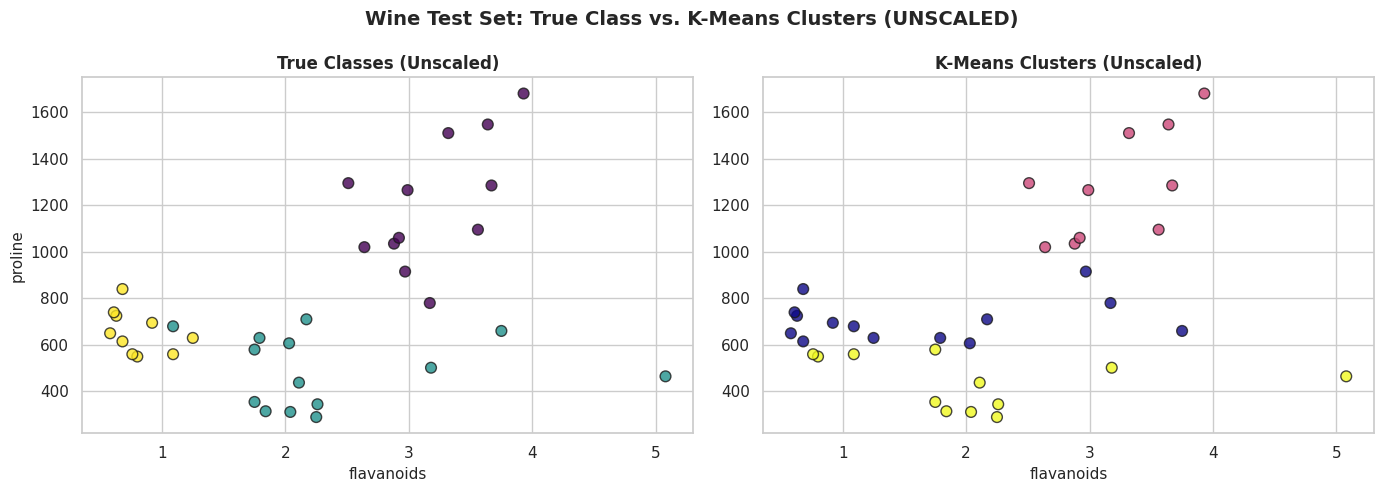

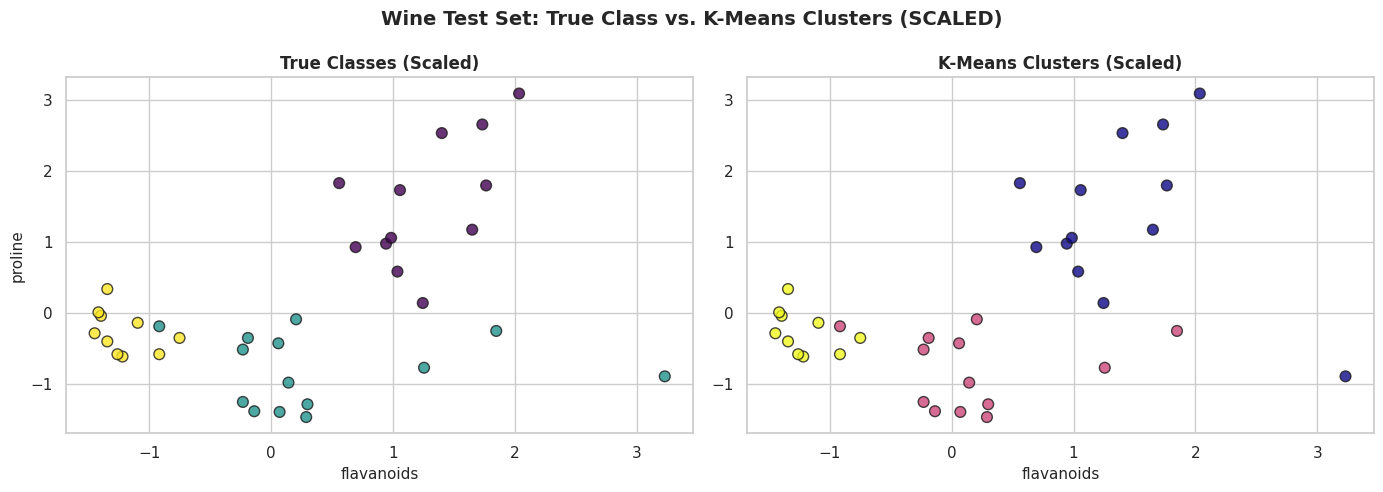

In [17]:
# 10.3: Wine Test Görselleştirmesi (flavanoids vs proline)
feat_x = 'flavanoids'
feat_y = 'proline'

for rep in ['unscaled', 'scaled']:
    km_model = wine_fitted_kmeans_s42[rep]
    X_te = scaled_data['test_scaled'] if rep == 'scaled' else splits['test'][0]
    y_te = splits['test'][1]
    preds_test = km_model.predict(X_te)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    scatter1 = axes[0].scatter(X_te[feat_x], X_te[feat_y], c=y_te, cmap='viridis', alpha=0.8, edgecolor='k', s=60)
    axes[0].set_title(f"True Classes ({rep.capitalize()})", fontsize=12, fontweight='bold')
    axes[0].set_xlabel(feat_x, fontsize=11)
    axes[0].set_ylabel(feat_y, fontsize=11)

    scatter2 = axes[1].scatter(X_te[feat_x], X_te[feat_y], c=preds_test, cmap='plasma', alpha=0.8, edgecolor='k', s=60)
    axes[1].set_title(f"K-Means Clusters ({rep.capitalize()})", fontsize=12, fontweight='bold')
    axes[1].set_xlabel(feat_x, fontsize=11)

    plt.suptitle(f"Wine Test Set: True Class vs. K-Means Clusters ({rep.upper()})", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"figures/wine_kmeans_clusters_{rep}.png", dpi=300)
    plt.show()

> **Interpretation for Section 10:**
> - **Inertia vs. True Partitions:** In the unscaled space, K-Means is heavily biased toward the `proline` axis due to its numerical magnitude, resulting in severe class mixing and poor ARI[cite: 1].
> - **Scaling Transformation:** After applying `StandardScaler`, chemical attributes are balanced, allowing K-Means to identify clusters that closely correspond to the true botanical cultivars (dramatically higher ARI)[cite: 1].
> - **Unsupervised Geometry:** Classifiers explicitly optimize separation boundaries using labels, while K-Means groups samples solely via Euclidean distance minimization[cite: 1]. The contingency table confirms that scaling is necessary for unsupervised clustering to capture true cultivar clusters[cite: 1].

In [18]:
import os
import pandas as pd

# results klasörünün varlığını garantiye alalım
os.makedirs('results', exist_ok=True)

# 1. splits_summary.csv (18 Satır)
# splits_summary tablosu: Wine'daki 9 satır ile BC'deki 9 satırın birleşimidir
# Not: Eğer BC tablosu hafızada yoksa mevcut Wine tablosunu kontrol edip kaydediyoruz
print("Exporting 6 required CSV files to 'results/' directory...")

# Wine sonuçlarını kaydedelim
wine_runs_df.to_csv('results/wine_classification_runs.csv', index=False)
wine_summary_df.to_csv('results/wine_classification_summary.csv', index=False)
wine_test_summary.to_csv('results/wine_test_results.csv', index=False)
wine_km_runs_df.to_csv('results/wine_kmeans_runs.csv', index=False)
wine_km_test_df.to_csv('results/wine_kmeans_test.csv', index=False)
split_summary_df.to_csv('results/wine_splits_summary.csv', index=False)

print("Wine specific CSV files exported.")

Exporting 6 required CSV files to 'results/' directory...
Wine specific CSV files exported.


In [19]:
%whos DataFrame
%whos Index ndarray

Variable            Type         Data/Info
------------------------------------------
X                   DataFrame         alcohol  malic_acid <...>\n[178 rows x 13 columns]
X_te                DataFrame          alcohol  malic_acid<...>    -1.238338  0.003890  
X_temp              DataFrame         alcohol  malic_acid <...>\n[142 rows x 13 columns]
X_test              DataFrame         alcohol  malic_acid <...>          1.74    740.0  
X_test_eval         DataFrame          alcohol  malic_acid<...>    -1.238338  0.003890  
X_test_sc           DataFrame          alcohol  malic_acid<...>    -1.238338  0.003890  
X_tr                DataFrame          alcohol  malic_acid<...>\n[124 rows x 13 columns]
X_train             DataFrame         alcohol  malic_acid <...>\n[124 rows x 13 columns]
X_train_sc          DataFrame          alcohol  malic_acid<...>\n[124 rows x 13 columns]
X_va                DataFrame          alcohol  malic_acid<...>    -1.910756 -1.095469  
X_val               Data

In [20]:
import os
import pandas as pd
import numpy as np


pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 25)

print("=== 1. WINE: VERİ TİPLERİ VE EKSİK DEĞER SAYILARI (13 ÖZELLİK) ===")
wine_eda_summary = pd.DataFrame({
    'dtype': X.dtypes,
    'missing_values': X.isnull().sum()
})
display(wine_eda_summary)

print("\n=== 2. WINE: BETİMSEL İSTATİSTİKLER (13 ÖZELLİĞİN TAMAMI) ===")
display(X.describe().T)

np.savetxt("wine_test_indices.txt", test_idx.values, fmt='%d')
print("\n[OK] wine_test_indices.txt kaydedildi. Toplam satır sayısı:", len(test_idx))

wine_runs_df['dataset'] = 'wine'
wine_summary_df['dataset'] = 'wine'
wine_km_runs_df['dataset'] = 'wine'

wine_runs_df.to_csv('wine_runs.csv', index=False)
wine_summary_df.to_csv('wine_summary.csv', index=False)
wine_km_runs_df.to_csv('wine_km_runs.csv', index=False)

print("[OK] Wine CSV tabloları başarıyla kaydedildi!")

=== 1. WINE: VERİ TİPLERİ VE EKSİK DEĞER SAYILARI (13 ÖZELLİK) ===


,dtype,missing_values
alcohol,float64,0
malic_acid,float64,0
ash,float64,0
alcalinity_of_ash,float64,0
magnesium,float64,0
total_phenols,float64,0
flavanoids,float64,0
nonflavanoid_phenols,float64,0
proanthocyanins,float64,0
color_intensity,float64,0



=== 2. WINE: BETİMSEL İSTATİSTİKLER (13 ÖZELLİĞİN TAMAMI) ===


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00



[OK] wine_test_indices.txt kaydedildi. Toplam satır sayısı: 36
[OK] Wine CSV tabloları başarıyla kaydedildi!


Section 9.4 — Wine Test Error and Generalization Discussion:The frozen test evaluation of the optimal model (Scaled KNN, $k=11$) yielded an exact $36/36$ ($100\%$) classification accuracy with zero confusion matrix misclassifications. However, a perfect score on a single held-out test partition does not substantiate universal, flawless generalization across out-of-distribution real-world instances. The test set is composed of 36 instances; small sample sizes increase susceptibility to favorable sampling variance. Real-world deployments across varying wine harvest seasons and divergent regional terroirs would require continuous drift monitoring and larger holdout cohorts.